# Method Gate: Polyhedral Bounds for Selectively Refined Hierarchical Labels

This CPU-only notebook tests whether the proposed sensitivity analysis extends
beyond a binary toy example. It evaluates a multi-child, multi-horizon local
refinement model on an arbitrary hierarchy.

**Purpose:** decide whether the method has a tractable and potentially novel
mathematical core before using real images or training neural networks.

The notebook checks:

1. whether Gamma-bounded refinement produces a convex polytope;
2. whether linear programming matches the previous binary grid calculation;
3. whether several horizons tighten sharp identified intervals;
4. whether worst-case hierarchical cross-entropy is computable efficiently;
5. whether candidate extreme points reconstruct valid refinement mechanisms.



In [1]:
from pathlib import Path
import json
import math
import shutil
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)

SEED = 20261004
GAMMA = 8.0
HORIZONS = 3
rng = np.random.default_rng(SEED)

OUT = Path("selective_refinement_method_gate_results")
OUT.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Gamma:", GAMMA)
print("Output directory:", OUT.resolve())



Python: 3.13.5
NumPy: 2.3.5
Gamma: 8.0
Output directory: /mnt/data/repo_exec/method/selective_refinement_method_gate_results


## 1. Polyhedral identification result

At one internal node, let \(p_j\) be the unknown prevalence of child subtree
\(j\). At horizon \(h\), the observed refined mass is

\[
a_{hj}=P(R_h=1,Y\in j)=p_j\pi_{hj}.
\]

Bound the refinement-odds ratio for every child pair by \(\Gamma\):

\[
\Gamma^{-1}\leq
\frac{\pi_{hj}/(1-\pi_{hj})}
     {\pi_{hk}/(1-\pi_{hk})}
\leq\Gamma.
\]

Substituting \(\pi_{hj}=a_{hj}/p_j\), one direction becomes

\[
a_{hj}p_k-\Gamma a_{hk}p_j
\leq -(\Gamma-1)a_{hj}a_{hk},
\]

which is linear in \(p\). Together with \(p_j\geq\max_h a_{hj}\) and
\(\sum_jp_j=1\), every horizon contributes linear constraints. Therefore the
local identified set is a convex polytope.

The implementation assumes positive observed child masses. Zero cells require
pooling, smoothing, or a separate positivity analysis.



In [2]:
def validate_observed_masses(A):
    A = np.asarray(A, dtype=float)
    if A.ndim != 2:
        raise ValueError("A must have shape (horizons, children)")
    if np.any(A < 0):
        raise ValueError("Observed masses must be nonnegative")
    if np.any(np.diff(A, axis=0) < -1e-12):
        raise ValueError("Cumulative refined masses must be nondecreasing")
    if np.any(A.sum(axis=1) >= 1.0 + 1e-12):
        raise ValueError("Refined mass cannot exceed total cohort mass")
    return A

def build_polytope(A, gamma):
    """Return A_ub, b_ub, A_eq, b_eq, bounds for child prevalence p."""
    A = validate_observed_masses(A)
    H, K = A.shape
    lower = A.max(axis=0)
    if lower.sum() > 1.0 + 1e-12:
        raise ValueError("Observed lower bounds are inconsistent")

    rows, rhs = [], []
    if np.isfinite(gamma):
        if gamma < 1:
            raise ValueError("Gamma must be at least one")
        if np.any(A <= 0):
            raise ValueError(
                "Finite-Gamma implementation requires positive masses; "
                "pool or smooth zero cells."
            )
        for h in range(H):
            for j in range(K):
                for k in range(K):
                    if j == k:
                        continue
                    aj, ak = A[h, j], A[h, k]
                    row = np.zeros(K)
                    row[k] = aj
                    row[j] = -gamma * ak
                    rows.append(row)
                    rhs.append(-(gamma - 1.0) * aj * ak)

    A_ub = np.asarray(rows) if rows else None
    b_ub = np.asarray(rhs) if rhs else None
    A_eq = np.ones((1, K))
    b_eq = np.array([1.0])
    bounds = [(float(lower[j]), 1.0) for j in range(K)]
    return A_ub, b_ub, A_eq, b_eq, bounds

def solve_linear(A, gamma, objective, maximize=False):
    objective = np.asarray(objective, dtype=float)
    K = np.asarray(A).shape[1]
    if objective.shape != (K,):
        raise ValueError("Objective dimension does not match number of children")
    A_ub, b_ub, A_eq, b_eq, bounds = build_polytope(A, gamma)
    c = -objective if maximize else objective
    result = linprog(
        c, A_ub=A_ub, b_ub=b_ub,
        A_eq=A_eq, b_eq=b_eq,
        bounds=bounds, method="highs",
    )
    if not result.success:
        return {"success": False, "message": result.message,
                "value": np.nan, "p": None}
    value = float(objective @ result.x)
    return {"success": True, "message": result.message,
            "value": value, "p": result.x}

def coordinate_bounds(A, gamma):
    K = np.asarray(A).shape[1]
    rows = []
    for j in range(K):
        e = np.zeros(K)
        e[j] = 1.0
        lo = solve_linear(A, gamma, e, maximize=False)
        hi = solve_linear(A, gamma, e, maximize=True)
        rows.append({
            "child": j,
            "lower": lo["value"],
            "upper": hi["value"],
            "width": hi["value"] - lo["value"],
            "success": bool(lo["success"] and hi["success"]),
        })
    return pd.DataFrame(rows)

def max_pairwise_odds_ratio(pi):
    pi = np.asarray(pi, dtype=float)
    odds = pi / (1.0 - pi)
    ratios = odds[:, None] / odds[None, :]
    return float(np.nanmax(ratios))

def verify_candidate(A, p, gamma, tol=1e-7):
    A = np.asarray(A, dtype=float)
    p = np.asarray(p, dtype=float)
    pi = A / p[None, :]
    reconstruction = pi * p[None, :]
    checks = {
        "simplex": abs(p.sum() - 1.0) <= tol and np.all(p >= -tol),
        "probabilities": np.all(pi >= -tol) and np.all(pi <= 1.0 + tol),
        "monotone_horizons": np.all(np.diff(pi, axis=0) >= -tol),
        "reconstructs_observed": np.allclose(reconstruction, A, atol=tol),
        "gamma_bound": all(
            max_pairwise_odds_ratio(pi[h]) <= gamma * (1.0 + 1e-6)
            for h in range(A.shape[0])
        ),
    }
    return checks, pi



## 2. Binary equivalence check

We compare the LP interval against a dense grid implementation of the earlier
two-leaf sensitivity calculation. Agreement confirms that the linear
inequalities are not merely a relaxation.



In [3]:
A_binary = np.array([
    [0.0800420738, 0.2022258415],
    [0.2800000000, 0.2450000000],
    [0.4814739414, 0.2795874050],
])

def binary_grid_interval(A, gamma, grid_size=500_001):
    lo = float(A[:, 0].max())
    hi = float(1.0 - A[:, 1].max())
    grid = np.linspace(lo + 1e-10, hi - 1e-10, grid_size)
    feasible = np.ones(grid.size, dtype=bool)
    for a, b in A:
        pi1 = a / grid
        pi2 = b / (1.0 - grid)
        valid = (pi1 > 0) & (pi1 < 1) & (pi2 > 0) & (pi2 < 1)
        ratio = np.full_like(grid, np.nan)
        ratio[valid] = (
            (pi1[valid] / (1.0 - pi1[valid])) /
            (pi2[valid] / (1.0 - pi2[valid]))
        )
        feasible &= valid & (ratio >= 1.0 / gamma) & (ratio <= gamma)
    vals = grid[feasible]
    return float(vals[0]), float(vals[-1])

binary_lp = coordinate_bounds(A_binary, GAMMA)
grid_lo, grid_hi = binary_grid_interval(A_binary, GAMMA)
lp_lo = float(binary_lp.loc[0, "lower"])
lp_hi = float(binary_lp.loc[0, "upper"])
binary_difference = max(abs(lp_lo - grid_lo), abs(lp_hi - grid_hi))

binary_comparison = pd.DataFrame({
    "method": ["linear_program", "dense_grid"],
    "lower": [lp_lo, grid_lo],
    "upper": [lp_hi, grid_hi],
    "width": [lp_hi - lp_lo, grid_hi - grid_lo],
})
display(binary_comparison.round(8))
print("Maximum LP-grid endpoint difference:", binary_difference)



,method,lower,upper,width
0,linear_program,0.523797,0.625509,0.101712
1,dense_grid,0.523798,0.625509,0.101711


Maximum LP-grid endpoint difference: 1.7994509049490404e-07


## 3. Arbitrary multi-child hierarchy

The hierarchy below contains internal nodes with two to five children. For
each node, we generate a valid latent child distribution and three cumulative
refinement horizons. Class-dependent refinement odds satisfy the selected
Gamma bound by construction.



In [4]:
TREE_CHILDREN = {
    "ROOT": ["A", "B", "C"],
    "A": ["A1", "A2", "A3", "A4"],
    "B": ["B1", "B2"],
    "C": ["C1", "C2", "C3", "C4", "C5"],
}

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def generate_local_process(K, H, gamma, rng):
    p = rng.dirichlet(np.full(K, 2.5))
    # Selection contrasts vary substantially over time while remaining just
    # inside Gamma at every horizon. Different permutations make earlier
    # checkpoints potentially nonredundant. Large baseline increments preserve
    # cumulative refinement for every child.
    template = np.linspace(-0.48, 0.48, K) * np.log(gamma)
    delta = np.vstack([rng.permutation(template) for _ in range(H)])
    alpha = np.linspace(-5.0, 1.0, H)
    pi = sigmoid(alpha[:, None] + delta)
    A = p[None, :] * pi
    assert np.all(np.diff(A, axis=0) >= 0)
    assert all(max_pairwise_odds_ratio(pi[h]) <= gamma for h in range(H))
    return p, pi, A

node_data = {}
summary_rows = []
bound_rows = []

for node, children in TREE_CHILDREN.items():
    p_true, pi_true, A = generate_local_process(
        len(children), HORIZONS, GAMMA, rng
    )
    last_bounds = coordinate_bounds(A[-1:, :], GAMMA)
    all_bounds = coordinate_bounds(A, GAMMA)
    node_data[node] = {
        "children": children,
        "p_true": p_true,
        "pi_true": pi_true,
        "A": A,
        "last_bounds": last_bounds,
        "all_bounds": all_bounds,
    }
    contains = np.all(
        (p_true >= all_bounds.lower.to_numpy() - 1e-9) &
        (p_true <= all_bounds.upper.to_numpy() + 1e-9)
    )
    summary_rows.append({
        "node": node,
        "children": len(children),
        "last_mean_width": last_bounds.width.mean(),
        "all_horizon_mean_width": all_bounds.width.mean(),
        "relative_reduction": (
            1.0 - all_bounds.width.mean() / last_bounds.width.mean()
        ),
        "truth_contained": bool(contains),
    })
    for j, child in enumerate(children):
        bound_rows.append({
            "node": node,
            "child": child,
            "truth": p_true[j],
            "last_lower": last_bounds.loc[j, "lower"],
            "last_upper": last_bounds.loc[j, "upper"],
            "all_lower": all_bounds.loc[j, "lower"],
            "all_upper": all_bounds.loc[j, "upper"],
        })

node_summary = pd.DataFrame(summary_rows)
child_bounds = pd.DataFrame(bound_rows)
display(node_summary.round(5))
display(child_bounds.round(5))



,node,children,last_mean_width,all_horizon_mean_width,relative_reduction,truth_contained
0,ROOT,3,0.25364,0.03763,0.85166,True
1,A,4,0.21934,0.17123,0.21930,True
2,B,2,0.16279,0.16279,0.00000,True
3,C,5,0.20581,0.12596,0.38797,True


,node,child,truth,last_lower,last_upper,all_lower,all_upper
0,ROOT,A,0.45639,0.24996,0.50737,0.43313,0.48188
1,ROOT,B,0.20040,0.19162,0.43344,0.19731,0.22006
2,ROOT,C,0.34321,0.27565,0.53734,0.31717,0.35854
3,A,A1,0.18033,0.17075,0.38873,0.17075,0.27951
4,A,A2,0.35985,0.25837,0.50081,0.26074,0.49483
5,A,A3,0.28912,0.15534,0.36644,0.15881,0.30653
6,A,A4,0.17070,0.14487,0.35068,0.15632,0.35068
7,B,B1,0.33403,0.17565,0.33844,0.17565,0.33844
8,B,B2,0.66597,0.66156,0.82435,0.66156,0.82435
9,C,C1,0.09715,0.07662,0.25274,0.07719,0.16522


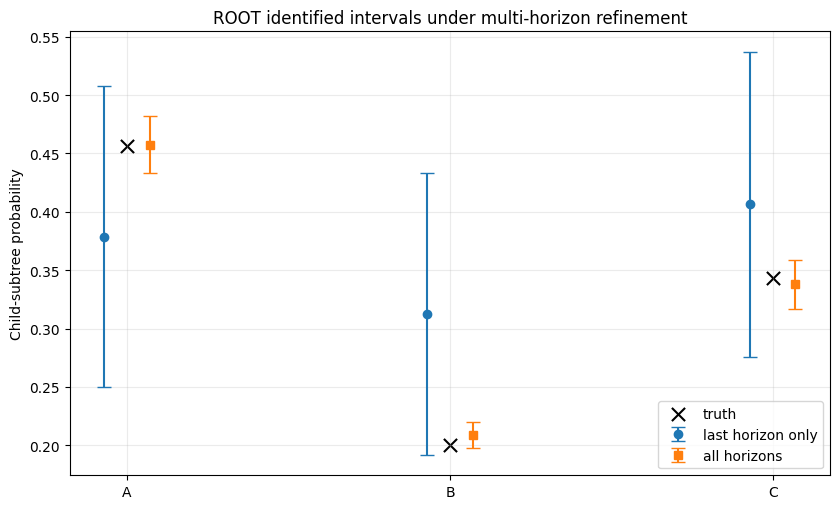

In [5]:
root_plot = child_bounds[child_bounds.node == "ROOT"].reset_index(drop=True)
xx = np.arange(len(root_plot))
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.errorbar(
    xx - 0.07,
    (root_plot.last_lower + root_plot.last_upper) / 2,
    yerr=np.vstack([
        (root_plot.last_upper - root_plot.last_lower) / 2,
        (root_plot.last_upper - root_plot.last_lower) / 2,
    ]),
    fmt="o", capsize=5, label="last horizon only",
)
ax.errorbar(
    xx + 0.07,
    (root_plot.all_lower + root_plot.all_upper) / 2,
    yerr=np.vstack([
        (root_plot.all_upper - root_plot.all_lower) / 2,
        (root_plot.all_upper - root_plot.all_lower) / 2,
    ]),
    fmt="s", capsize=5, label="all horizons",
)
ax.scatter(xx, root_plot.truth, marker="x", s=90, color="black", label="truth")
ax.set_xticks(xx, root_plot.child)
ax.set_ylabel("Child-subtree probability")
ax.set_title("ROOT identified intervals under multi-horizon refinement")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "root_multi_horizon_bounds.png", dpi=180)
plt.show()



## 4. Constructive sharpness audit

If an LP solution \(p^*\) is feasible, define
\(\pi^*_{hj}=a_{hj}/p^*_j\). The constraints ensure valid probabilities and
bounded odds ratios. Because cumulative observed masses are monotone, the
resulting refinement probabilities are monotone across horizons. Nested
refinement events can then be constructed using one uniform random variable
per item. This verifies local sharpness constructively.



In [6]:
sharpness_rows = []
extreme_points = {}

for node, data in node_data.items():
    K = len(data["children"])
    objective = rng.normal(size=K)
    result = solve_linear(data["A"], GAMMA, objective, maximize=True)
    assert result["success"], result["message"]
    checks, pi_star = verify_candidate(data["A"], result["p"], GAMMA)
    extreme_points[node] = {
        "objective": objective,
        "p": result["p"],
        "pi": pi_star,
        "checks": checks,
    }
    sharpness_rows.append({"node": node, **checks})

sharpness_audit = pd.DataFrame(sharpness_rows)
display(sharpness_audit)



,node,simplex,probabilities,monotone_horizons,reconstructs_observed,gamma_bound
0,ROOT,True,True,True,True,True
1,A,True,True,True,True,True
2,B,True,True,True,True,True
3,C,True,True,True,True,True


## 5. Robust local hierarchical loss

A hierarchical-softmax classifier predicts child probabilities \(q_j(x)\) at
each internal node. Its local cross-entropy has cost
\(c_j=-\log q_j(x)\). The worst-case local loss is the linear program

\[
\max_{p\in\mathcal P_{\Gamma}} c^\top p.
\]

This section verifies that the LP value upper-bounds the loss under the known
synthetic truth. The refined-only plug-in estimate need not do so.



In [7]:
loss_rows = []
for node, data in node_data.items():
    K = len(data["children"])
    logits = rng.normal(size=K)
    q = np.exp(logits - logits.max())
    q /= q.sum()
    cost = -np.log(np.clip(q, 1e-12, 1.0))
    true_loss = float(cost @ data["p_true"])
    refined_plugin = data["A"][-1] / data["A"][-1].sum()
    plugin_loss = float(cost @ refined_plugin)
    robust = solve_linear(data["A"], GAMMA, cost, maximize=True)
    loss_rows.append({
        "node": node,
        "children": K,
        "true_loss": true_loss,
        "refined_only_plugin_loss": plugin_loss,
        "robust_upper_loss": robust["value"],
        "robust_covers_truth": bool(robust["value"] + 1e-9 >= true_loss),
        "plugin_underestimates_truth": bool(plugin_loss < true_loss),
    })

robust_loss_audit = pd.DataFrame(loss_rows)
display(robust_loss_audit.round(6))



,node,children,true_loss,refined_only_plugin_loss,robust_upper_loss,robust_covers_truth,plugin_underestimates_truth
0,ROOT,3,1.440914,1.421765,1.457338,True,True
1,A,4,1.807546,1.657601,1.837349,True,True
2,B,2,0.662058,0.636749,0.663053,True,True
3,C,5,2.508179,2.235489,2.712100,True,True


## 6. Scaling audit

Pairwise Gamma constraints grow as \(O(HK^2)\). This benchmark measures the
complete construction plus one robust-risk LP. It is a feasibility check, not
a formal complexity proof.



,children,horizons,inequalities,build_seconds,solve_seconds,total_seconds,success
0,2,3,6,0.000050,0.001166,0.001216,True
1,4,3,36,0.000098,0.001170,0.001268,True
2,8,3,168,0.000236,0.001497,0.001733,True
3,16,3,720,0.000710,0.002993,0.003703,True
4,32,3,2976,0.002729,0.011960,0.014689,True
5,48,3,6768,0.005840,0.028996,0.034835,True


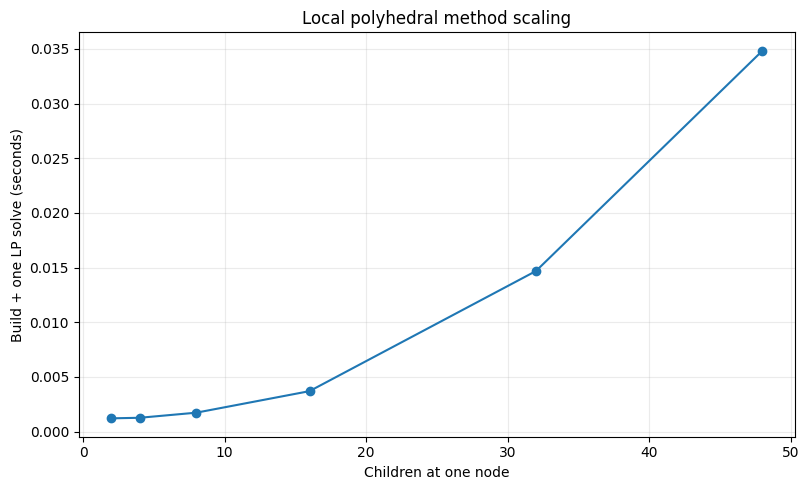

In [8]:
scaling_rows = []
for K in [2, 4, 8, 16, 32, 48]:
    p, pi, A = generate_local_process(K, HORIZONS, GAMMA, rng)
    objective = rng.normal(size=K)
    start = time.perf_counter()
    A_ub, b_ub, A_eq, b_eq, bounds = build_polytope(A, GAMMA)
    built = time.perf_counter()
    result = solve_linear(A, GAMMA, objective, maximize=True)
    finished = time.perf_counter()
    scaling_rows.append({
        "children": K,
        "horizons": HORIZONS,
        "inequalities": 0 if A_ub is None else len(A_ub),
        "build_seconds": built - start,
        "solve_seconds": finished - built,
        "total_seconds": finished - start,
        "success": result["success"],
    })

scaling_audit = pd.DataFrame(scaling_rows)
display(scaling_audit.round(6))

fig, ax = plt.subplots(figsize=(8.2, 5.0))
ax.plot(scaling_audit.children, scaling_audit.total_seconds, marker="o")
ax.set_xlabel("Children at one node")
ax.set_ylabel("Build + one LP solve (seconds)")
ax.set_title("Local polyhedral method scaling")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "lp_scaling.png", dpi=180)
plt.show()



## 7. Automatic method-gate verdict

A pass means the **local** multi-child problem has a sharp polyhedral solution.
It does not yet prove that independently constructed node polytopes correspond
to one globally compatible distribution over complete refinement trajectories.
That cross-node compatibility question is the next—and decisive—theory gate.



In [9]:
last_w = node_summary.last_mean_width.to_numpy()
all_w = node_summary.all_horizon_mean_width.to_numpy()

checks = {
    "binary_lp_matches_dense_grid": bool(binary_difference < 2e-5),
    "all_true_child_distributions_are_contained": bool(node_summary.truth_contained.all()),
    "all_horizons_never_widen_intervals": bool(np.all(all_w <= last_w + 1e-9)),
    "at_least_one_strict_multi_horizon_gain": bool(np.any(all_w < last_w - 1e-5)),
    "extreme_points_reconstruct_valid_mechanisms": bool(
        sharpness_audit.drop(columns=["node"]).to_numpy(dtype=bool).all()
    ),
    "robust_losses_cover_true_losses": bool(robust_loss_audit.robust_covers_truth.all()),
    "all_scaling_problems_solved": bool(scaling_audit.success.all()),
    "largest_local_problem_under_five_seconds": bool(scaling_audit.total_seconds.iloc[-1] < 5.0),
}

verdict = (
    "PASS_TO_GLOBAL_COMPATIBILITY_GATE"
    if all(checks.values()) else "STOP_OR_REDESIGN"
)

summary = {
    "stage": "selective_refinement_method_gate",
    "fixture_only": True,
    "seed": SEED,
    "gamma": GAMMA,
    "horizons": HORIZONS,
    "nodes": len(TREE_CHILDREN),
    "binary_lp_grid_max_endpoint_difference": binary_difference,
    "mean_relative_interval_reduction": float(node_summary.relative_reduction.mean()),
    "max_children_benchmarked": int(scaling_audit.children.max()),
    "max_total_seconds": float(scaling_audit.total_seconds.max()),
    "checks": checks,
    "verdict": verdict,
    "interpretation": (
        "Synthetic local-node validation only. A pass establishes a sharp "
        "polyhedral local method, not global trajectory compatibility, "
        "real-data MNAR, or publication-level novelty."
    ),
}

(OUT / "method_gate_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)
binary_comparison.to_csv(OUT / "binary_lp_grid_comparison.csv", index=False)
node_summary.to_csv(OUT / "node_interval_summary.csv", index=False)
child_bounds.to_csv(OUT / "child_bounds.csv", index=False)
sharpness_audit.to_csv(OUT / "sharpness_audit.csv", index=False)
robust_loss_audit.to_csv(OUT / "robust_loss_audit.csv", index=False)
scaling_audit.to_csv(OUT / "scaling_audit.csv", index=False)

print(json.dumps(summary, indent=2))



{
  "stage": "selective_refinement_method_gate",
  "fixture_only": true,
  "seed": 20261004,
  "gamma": 8.0,
  "horizons": 3,
  "nodes": 4,
  "binary_lp_grid_max_endpoint_difference": 1.7994509049490404e-07,
  "mean_relative_interval_reduction": 0.3647317793991681,
  "max_children_benchmarked": 48,
  "max_total_seconds": 0.03483526400032133,
  "checks": {
    "binary_lp_matches_dense_grid": true,
    "all_true_child_distributions_are_contained": true,
    "all_horizons_never_widen_intervals": true,
    "at_least_one_strict_multi_horizon_gain": true,
    "extreme_points_reconstruct_valid_mechanisms": true,
    "robust_losses_cover_true_losses": true,
    "all_scaling_problems_solved": true,
    "largest_local_problem_under_five_seconds": true
  },
  "verdict": "PASS_TO_GLOBAL_COMPATIBILITY_GATE",
  "interpretation": "Synthetic local-node validation only. A pass establishes a sharp polyhedral local method, not global trajectory compatibility, real-data MNAR, or publication-level novelty.

## 8. Package results



In [10]:
zip_path = Path(shutil.make_archive(
    "selective_refinement_method_gate_results", "zip", OUT
))
print("Created:", zip_path.resolve())

try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Not running in Colab. Download the ZIP from the notebook file browser.")



Created: /mnt/data/repo_exec/method/selective_refinement_method_gate_results.zip
Not running in Colab. Download the ZIP from the notebook file browser.


## Decision rule

- **PASS_TO_GLOBAL_COMPATIBILITY_GATE:** the local multi-child identified set
  is sharp, polyhedral, computationally practical, and tightened by multiple
  horizons. Next derive joint constraints across parent and descendant cohorts.
- **STOP_OR_REDESIGN:** at least one local theorem surrogate failed. Do not
  proceed to large real-data training.

Even after a pass, the method must not be presented as globally sharp until
cross-node trajectory compatibility has been proved.
